In [2]:
!pip -q install -U datasets huggingface_hub pyarrow pandas matplotlib seaborn

from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("HF_TOKEN"))
print("logged in")

logged in


In [3]:
from datasets import load_dataset
import pandas as pd

REPO = "TheFireHacker/bubblspace-relational-passages-Qwen3-30B"

kept = load_dataset(REPO, split="train")
rej = load_dataset(REPO, "rejected", split="train")

df = kept.to_pandas()
dfr = rej.to_pandas()

print("kept:", len(df), "rejected:", len(dfr))
print("pass rate: {:.1%}".format(len(df) / (len(df) + len(dfr))))
print("kept columns:", list(df.columns))
print("rejected columns:", list(dfr.columns))
df.head(3)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


README.md:   0%|          | 0.00/7.39k [00:00<?, ?B/s]

data/train-00000.parquet: reconstructing file:   0%|          |  0.00B / 6.01MB            

data/train-00000.parquet: downloading bytes:           |  0.00B            

data/train-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.00MB            

data/train-00001.parquet: downloading bytes:           |  0.00B            

... (12 outputs left out)

rejected/rejected-00003.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

kept: 38335 rejected: 40962
pass rate: 48.3%
kept columns: ['text', 'mode', 'relation', 'format', 'level', 'topic', 'source_title', 'source_url', 'idx']
rejected columns: ['text', 'critique', 'mode', 'relation', 'format', 'source_title', 'idx']


,text,mode,relation,format,level,topic,source_title,source_url,idx
0,People sometimes mix up what a public official...,grounded,input_output,confusion,a general adult reader,None,John Rose (Minnesota politician),https://en.wikipedia.org/wiki/John%20Rose%20%2...,0
1,People often confuse the drachma with the obol...,grounded,contrast_concession,confusion,a general adult reader,None,Ancient drachma,https://en.wikipedia.org/wiki/Ancient%20drachma,4
2,People sometimes mix up how N-World and Mirai ...,grounded,spatial,confusion,a general adult reader,None,N-World,https://en.wikipedia.org/wiki/N-World,5


In [4]:
import re

def word_count(t):
    return len(re.findall(r"\S+", t or ""))

df["n_words"] = df["text"].map(word_count)
df["n_chars"] = df["text"].map(lambda t: len(t or ""))
dfr["n_words"] = dfr["text"].map(word_count)
dfr["n_chars"] = dfr["text"].map(lambda t: len(t or ""))

print("KEPT words describe:")
print(df["n_words"].describe())
print("\nREJECTED words describe:")
print(dfr["n_words"].describe())
print("\nkept under 80 words:", int((df["n_words"] < 80).sum()))
print("approx kept tokens (words*1.3):", int(df["n_words"].sum() * 1.3))

KEPT words describe:
count    38335.000000
mean       246.652563
std         58.651670
min        112.000000
25%        198.000000
50%        244.000000
75%        293.000000
max        446.000000
Name: n_words, dtype: float64

REJECTED words describe:
count    40962.000000
mean       247.779625
std         59.678796
min        126.000000
25%        193.000000
50%        248.000000
75%        295.000000
max        613.000000
Name: n_words, dtype: float64

kept under 80 words: 0
approx kept tokens (words*1.3): 12292053


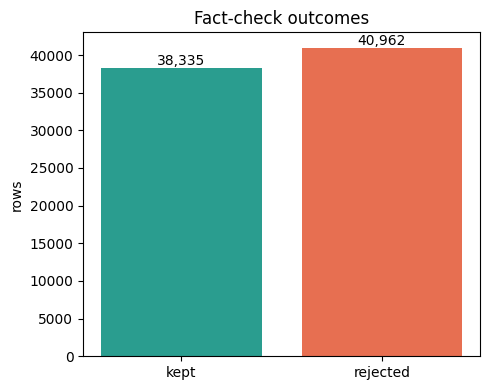

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["kept", "rejected"], [len(df), len(dfr)], color=["#2a9d8f", "#e76f51"])
ax.set_title("Fact-check outcomes")
ax.set_ylabel("rows")
for i, v in enumerate([len(df), len(dfr)]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

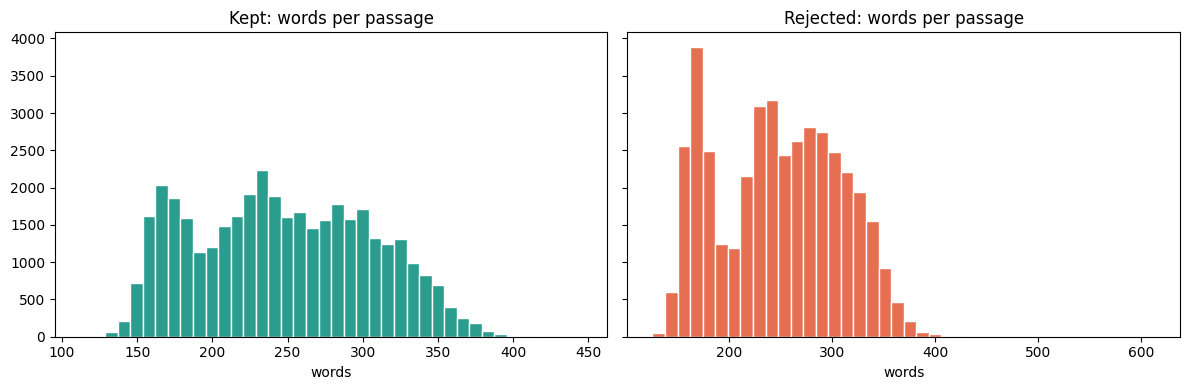

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(df["n_words"], bins=40, color="#2a9d8f", edgecolor="white")
axes[0].set_title("Kept: words per passage")
axes[0].set_xlabel("words")
axes[1].hist(dfr["n_words"], bins=40, color="#e76f51", edgecolor="white")
axes[1].set_title("Rejected: words per passage")
axes[1].set_xlabel("words")
plt.tight_layout()
plt.show()

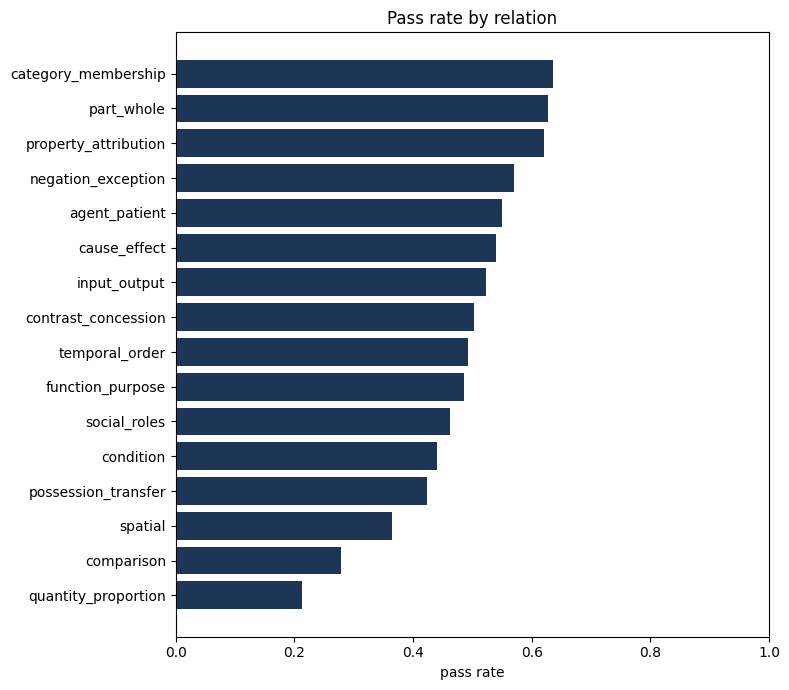

,kept,rejected,pass_rate
relation,,,
category_membership,3190,1825,0.636092
part_whole,3088,1833,0.627515
property_attribution,3027,1850,0.620668
negation_exception,2875,2165,0.570437
agent_patient,2726,2228,0.550262
cause_effect,2659,2264,0.540118
input_output,2668,2433,0.523035
contrast_concession,2513,2491,0.502198
temporal_order,2488,2553,0.493553


In [7]:
kr = df["relation"].value_counts()
rr = dfr["relation"].value_counts()
pass_rel = pd.DataFrame({"kept": kr, "rejected": rr}).fillna(0)
pass_rel["pass_rate"] = pass_rel["kept"] / (pass_rel["kept"] + pass_rel["rejected"])
pass_rel = pass_rel.sort_values("pass_rate", ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(pass_rel.index, pass_rel["pass_rate"], color="#1d3557")
ax.set_xlim(0, 1)
ax.set_xlabel("pass rate")
ax.set_title("Pass rate by relation")
plt.tight_layout()
plt.show()
pass_rel.sort_values("pass_rate", ascending=False)

In [8]:
from IPython.display import display, Markdown

i = 0  # change this to any row number
row = df.iloc[i]

display(Markdown(
    f"**row {i} | {row['format']} | {row['relation']} | {row['source_title']}**\n\n"
    + row["text"]
))

**row 0 | confusion | input_output | John Rose (Minnesota politician)**

People sometimes mix up what a public official does with what results from their work. Specifically, they may confuse the effort a politician puts in—like working with others across party lines—with the actual outcome, such as new laws or community projects. In reality, the process (the effort) is about collaboration and negotiation. For example, the source says John Rose worked across the aisle to get votes for legislation. This means his daily actions involved listening, compromising, and building support—these are the inputs. The outputs, or results, are the laws passed or projects funded that help people in his district.

Another common mix-up is confusing the role of a teacher with the value of a sports facility named after them. Rose was a physical education teacher, so his job was to teach students how to stay active and healthy. That’s an input: his time, energy, and instruction in the classroom. But the output is something different—the Guidant John Rose Minnesota Oval, a sports facility named in his honor. This oval wasn’t created by his teaching, but by his later political work and support for youth sports. The facility is a lasting result of his advocacy, not a direct product of his classroom teaching.

The confusion happens because both teaching and public service involve helping youth and supporting communities. But one is a daily job (input), while the other is a long-term benefit (output), and the two aren’t the same thing, even when linked by a person’s values and dedication.

In [9]:
# blank / missing topic in kept
blank = df["topic"].isna() | (df["topic"].astype(str).str.strip() == "") | (df["topic"].astype(str) == "None")

print("kept rows:", len(df))
print("topic blank/missing:", int(blank.sum()))
print("topic filled:", int((~blank).sum()))
print("blank rate: {:.1%}".format(blank.mean()))

# see what values exist
print("\nvalue counts (including NaN):")
print(df["topic"].value_counts(dropna=False).head(20))

kept rows: 38335
topic blank/missing: 38335
topic filled: 0
blank rate: 100.0%

value counts (including NaN):
topic
None    38335
Name: count, dtype: int64


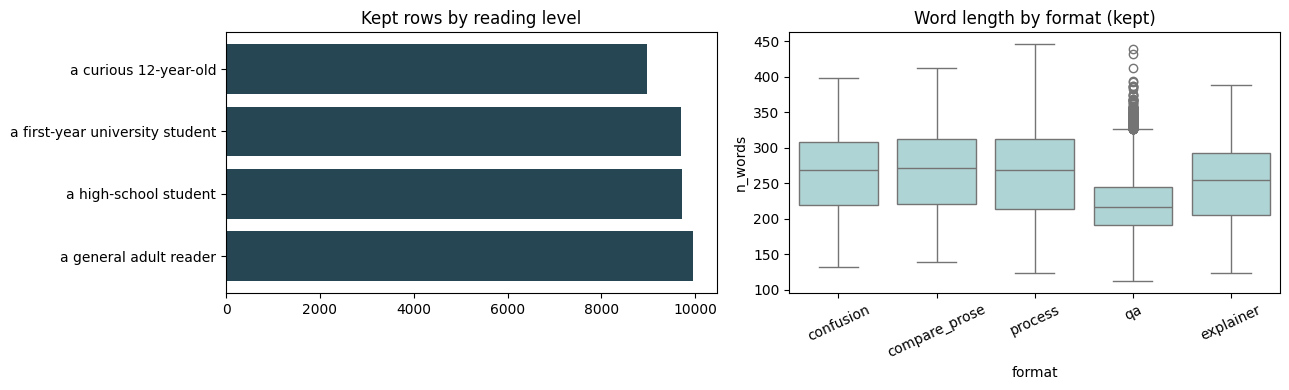

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lvl = df["level"].value_counts()
axes[0].barh(lvl.index, lvl.values, color="#264653")
axes[0].set_title("Kept rows by reading level")

sns.boxplot(data=df, x="format", y="n_words", ax=axes[1], color="#a8dadc")
axes[1].set_title("Word length by format (kept)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

unique Wikipedia titles in kept: 37,965 / 38,335 rows
max repeats of one title: 2


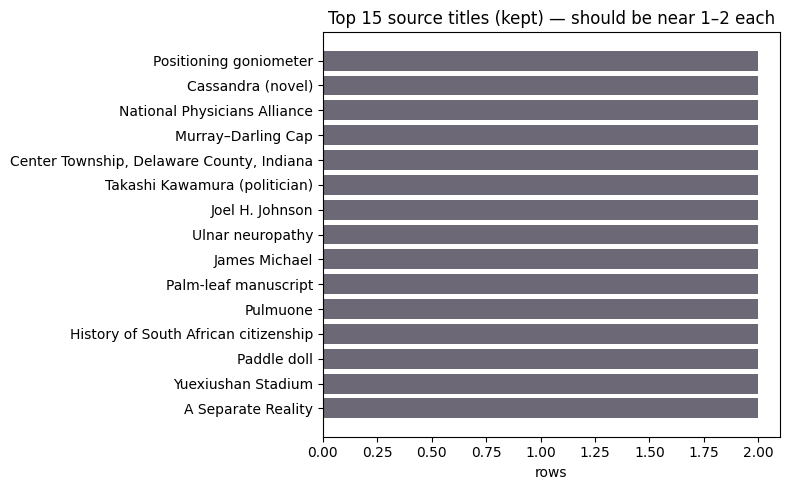

In [12]:
n_unique = df["source_title"].nunique()
top = df["source_title"].value_counts().head(15)

print(f"unique Wikipedia titles in kept: {n_unique:,} / {len(df):,} rows")
print("max repeats of one title:", int(df["source_title"].value_counts().max()))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.values[::-1], color="#6d6875")
ax.set_title("Top 15 source titles (kept) — should be near 1–2 each")
ax.set_xlabel("rows")
plt.tight_layout()
plt.show()

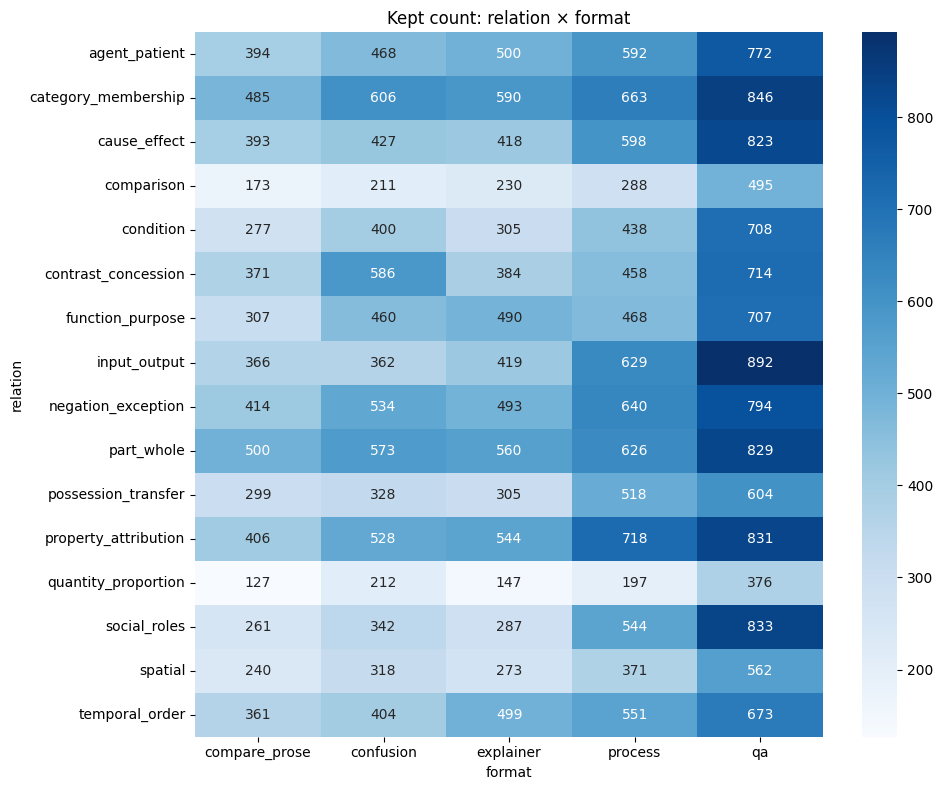

In [13]:
ct = pd.crosstab(df["relation"], df["format"])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Kept count: relation × format")
plt.tight_layout()
plt.show()

In [14]:
from IPython.display import display, Markdown

print("=== 1 kept sample per format ===")
for fmt, g in df.groupby("format"):
    row = g.sample(1, random_state=0).iloc[0]
    display(Markdown(
        f"**format=`{fmt}` | relation=`{row.relation}` | {row.source_title}**\n\n"
        + row.text[:700].replace("\n", "\n\n")
        + ("…" if len(row.text) > 700 else "")
    ))

print("\n=== 5 random reject critiques ===")
for _, row in dfr.sample(5, random_state=1).iterrows():
    crit = (row.get("critique") or "")[:500]
    display(Markdown(
        f"**FAIL | `{row.format}` | `{row.relation}` | {row.source_title}**\n\n{crit}"
    ))

=== 1 kept sample per format ===


**format=`compare_prose` | relation=`possession_transfer` | Brian Rogers (baseball)**

The Detroit Tigers, as the team that selected him in the draft, owned Brian Rogers’ professional rights and determined his early career path. He received assignments to various minor league teams, starting with the Low-A Oneonta Tigers, where he was given the opportunity to begin his development as a starting pitcher. Later, the same organization promoted him to higher levels, showing trust in his abilities. The former team, Oneonta, provided him with a platform to gain experience, while the latter, West Michigan, offered a step up in competition. At West Michigan, he continued to pitch, though results were inconsistent, with a higher earned run average suggesting he struggled to maintain ef…

**format=`confusion` | relation=`contrast_concession` | MODAF**

People often mix up what MODAF *is* and what the M3 *is*, even though they’re closely connected. They sound similar because both are part of the same system, but they’re not the same thing at all.



MODAF is like a set of special drawing tools that help teams explain how a business or military operation works. It gives different views—like different camera angles—so that people with different jobs (like planners, engineers, or leaders) can see the big picture from their own point of view. These views are usually shown as pictures or diagrams that make complex ideas easier to understand.



The M3, on the other hand, isn’t a view or a picture. It’s the hidden rulebook behind the scenes. Think of…

**format=`explainer` | relation=`possession_transfer` | Pediatric Oncology Group**

The National Cancer Institute (NCI) owns and supports the caBIG initiative, which aims to integrate databases from multiple pediatric cancer research groups. The NCI gives guidance and funding to this effort, enabling the consolidation of data from different organizations. The Pediatric Oncology Group (POG) receives support from the NCI through its involvement with caBIG, as POG’s data and systems are part of this larger integration project. In turn, POG owes its participation in quality assurance to the NCI’s mandate, as all POG radiotherapy departments must submit their data to the Quality Assurance Review Center (QARC). QARC, located in Lincoln, Rhode Island, receives radiotherapy data fr…

**format=`process` | relation=`quantity_proportion` | Secret Agent (Robin Gibb album)**

Robin and Maurice began by bringing only song ideas into the studio, not fully written songs. From these ideas, they created lyrics together, with Robin handling the words and Maurice contributing musically. Next, they built the foundation of each song by setting up drum and synthesizer rhythms, which served as the starting point for the rest of the track. This initial groove was more than just a background—it shaped the entire direction of the music. Maurice played synthesizer and keyboard during this phase, but on the final version of the album, he played less than half of the keyboard parts, as Rob Kilgore took over most of the keyboard duties. The team used more of Rob Kilgore’s work tha…

**format=`qa` | relation=`category_membership` | Frances Margaret Leighton**

What is a monograph, and how is it different from a general textbook?  

A monograph is a detailed scholarly study on a single subject, unlike a textbook which covers broad topics. Frances Leighton wrote monographs on specific plant groups, showing in-depth research.



Who was William Edwyn Isaac, and how does his work differ from Frances’s?  

He was a marine botanist focusing on sea plants, while Frances specialized in land-based monocots. Their work covered different environments and plant types.



Why did Frances move to Nairobi, and how was her role there different from her earlier job?  

She moved to support her husband’s academic role; in Nairobi, she studied seagrasses and taught adult w…

... (2 outputs left out)

**FAIL | `process` | `comparison` | Gregory Kirchhoff**

The generated text inaccurately implies the screenplay was "smaller in size" without basis in the source, and incorrectly suggests the filmmaker was offered a role directing a new project—Kirchhoff was offered the director role, not an acting role. The text also generalizes award prestige without evidence, and misrepresents the nature of the TV movie's release as a "larger audience reach" due to theatrical distribution, which is not inherently true for all such films.

VERDICT: FAIL

**FAIL | `explainer` | `contrast_concession` | 26th Ohio Independent Light Artillery Battery**

The generated text correctly distinguishes the roles of artillery and infantry, and accurately reflects the 26th Ohio Battery's detachment from the 32nd Ohio Infantry on December 22, 1863. However, it incorrectly implies the 32nd Ohio Infantry remained focused on guarding and marching, while the battery was involved in major battles—this is misleading, as the 32nd Ohio Infantry was also engaged in significant combat actions, including Vicksburg and the Meridian Campaign, and the battery's moveme

**FAIL | `confusion` | `contrast_concession` | Paolo Pizzetti**

The generated text correctly states that Pizzetti studied engineering and later taught geodesy, aligning with the source. However, it inaccurately implies he remained in Rome after graduating to work with Pisati and Pucci—while the source confirms he stayed in Rome initially, it does not specify he worked with them immediately after graduation, and his role in gravity measurements is not detailed in the source. Additionally, the claim that he "spent the rest of his life" in Pisa is misleading, a

**FAIL | `compare_prose` | `part_whole` | Philip Henry**

The generated text accurately reflects the source regarding Henry's education at Westminster School, his status as a King’s Scholar, his studies in Greek and Latin, his association with Richard Busby, and his religious awakening after hearing Stephen Marshal. However, it incorrectly implies that Busby prepared Henry for holy communion, as the source states Henry himself credits Busby with this preparation, not the other way around. Additionally, the text misrepresents the timeline by suggesting 

In [15]:
summary = pd.DataFrame({
    "metric": [
        "kept_rows", "rejected_rows", "pass_rate",
        "kept_total_words", "kept_median_words",
        "unique_sources", "formats", "relations",
    ],
    "value": [
        len(df), len(dfr), f"{len(df)/(len(df)+len(dfr)):.1%}",
        int(df["n_words"].sum()), int(df["n_words"].median()),
        int(df["source_title"].nunique()),
        df["format"].nunique(), df["relation"].nunique(),
    ],
})
summary

,metric,value
0,kept_rows,38335
1,rejected_rows,40962
2,pass_rate,48.3%
3,kept_total_words,9455426
4,kept_median_words,244
5,unique_sources,37965
6,formats,5
7,relations,16


# EDA for Claude Code to decde if relations that dont make much sense need to be stopped from generation

In [16]:
kf = df["format"].value_counts()
rf = dfr["format"].value_counts()
pass_fmt = pd.DataFrame({"kept": kf, "rejected": rf}).fillna(0)
pass_fmt["pass_rate"] = pass_fmt["kept"] / (pass_fmt["kept"] + pass_fmt["rejected"])
pass_fmt.sort_values("pass_rate", ascending=False)

,kept,rejected,pass_rate
format,,,
qa,11459,4314,0.726495
process,8299,7509,0.524987
confusion,6759,8996,0.429007
explainer,6444,9347,0.408081
compare_prose,5374,10796,0.332344


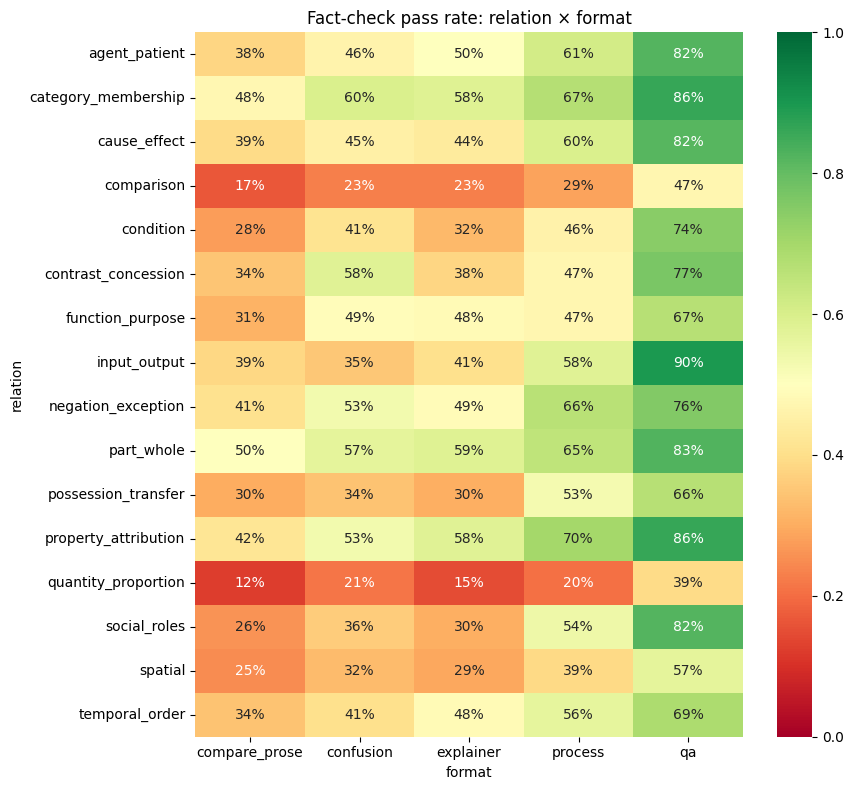

In [17]:
import seaborn as sns

k = df.groupby(["relation", "format"]).size()
r = dfr.groupby(["relation", "format"]).size()
both = pd.DataFrame({"kept": k, "rej": r}).fillna(0)
both["pass_rate"] = both["kept"] / (both["kept"] + both["rej"])
heat = both["pass_rate"].unstack("format")

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(heat, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Fact-check pass rate: relation × format")
plt.tight_layout(); plt.show()

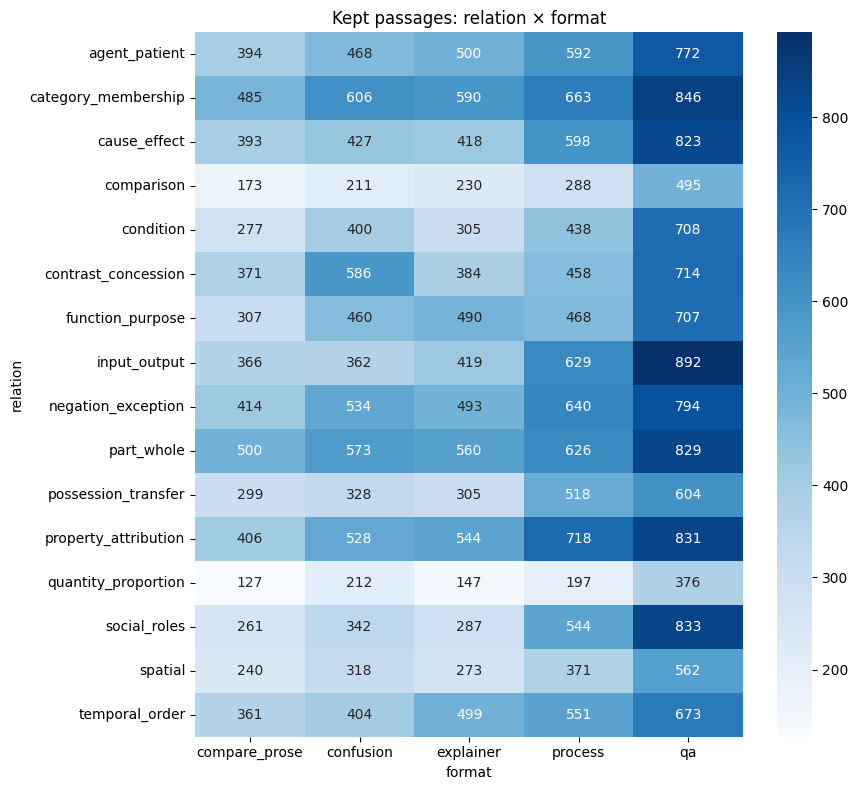

In [18]:
counts = df.groupby(["relation", "format"]).size().unstack("format").fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Kept passages: relation × format")
plt.tight_layout(); plt.show()

domain
other       0.374
place       0.152
person      0.130
media       0.121
sports      0.083
business    0.055
biology     0.045
history     0.040
Name: proportion, dtype: float64


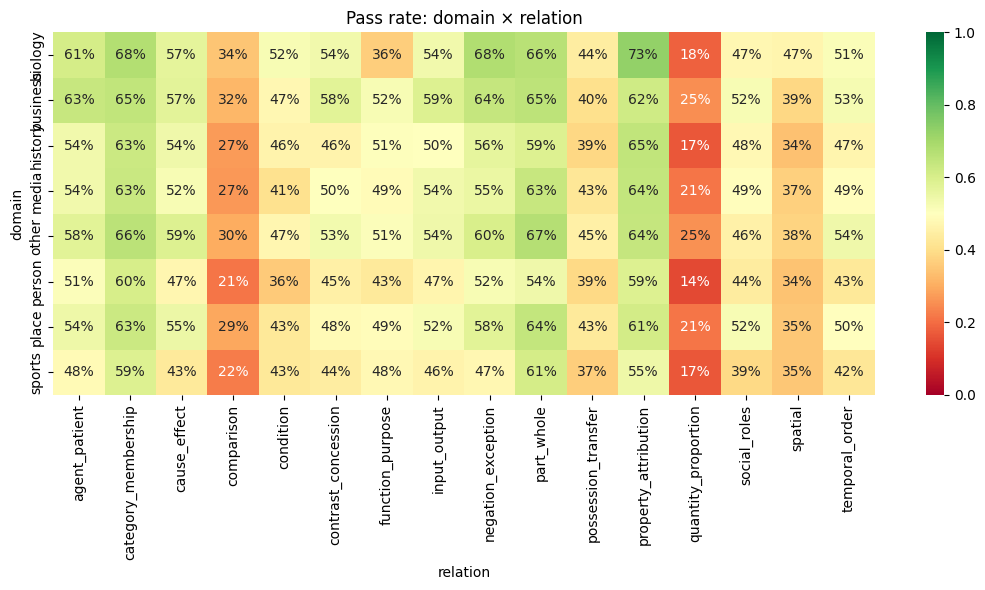

In [19]:
import re

def guess_domain(text):
    t = text.lower()
    if re.search(r"\b(born|died|his career|her career|was elected|served as|played for)\b", t): return "person"
    if re.search(r"\b(village|town|city|district|county|province|river|located in)\b", t): return "place"
    if re.search(r"\b(species|genus|plant|animal|bird|fish|insect|habitat)\b", t): return "biology"
    if re.search(r"\b(album|song|film|novel|band|episode|series)\b", t): return "media"
    if re.search(r"\b(war|battle|empire|dynasty|treaty|revolution)\b", t): return "history"
    if re.search(r"\b(team|season|league|match|championship|tournament)\b", t): return "sports"
    if re.search(r"\b(company|business|market|founded|brand)\b", t): return "business"
    return "other"

df["domain"] = df["text"].map(guess_domain)
dfr["domain"] = dfr["text"].map(guess_domain)
print(df["domain"].value_counts(normalize=True).round(3))

kd = df.groupby(["domain", "relation"]).size()
rd = dfr.groupby(["domain", "relation"]).size()
dom = pd.DataFrame({"kept": kd, "rej": rd}).fillna(0)
dom["pass_rate"] = dom["kept"] / (dom["kept"] + dom["rej"])
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(dom["pass_rate"].unstack("relation"), annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Pass rate: domain × relation")
plt.tight_layout(); plt.show()

In [20]:
from IPython.display import display, Markdown

FORMAT, RELATION, N = "confusion", "input_output", 5   # edit me
sub = df[(df["format"] == FORMAT) & (df["relation"] == RELATION)]
print(f"{len(sub)} kept passages for {FORMAT} × {RELATION}")
for _, row in sub.sample(min(N, len(sub)), random_state=0).iterrows():
    display(Markdown(f"---\n**{row['source_title']}** · {row['level']}\n\n{row['text']}"))

362 kept passages for confusion × input_output


---
**State Highway 21 (Kerala)** · a general adult reader

People often mix up what the road itself does versus what it allows. The road is not a process that creates something; it is a path that enables movement. The real input is the journey — the travel of vehicles and people along the route. The output is access: the ability to reach destinations like the waterfalls, viewpoints, and forest checkposts. But the road doesn’t produce these places — it only connects to them. The actual outputs of the journey are not physical objects but experiences: views of waterfalls, access to reservoirs, or the chance to see forested landscapes. The road simply provides the way to get there, not the destination itself.

Another common mix-up is between what the forest checkposts control and what they represent. The checkposts are not places where something is made or grown. They are points where access is regulated. The input is the vehicle and its traveler trying to enter the forest area. The output is permission — or denial — to proceed, based on time rules and forest laws. The checkposts do not generate the forest, the rivers, or the waterfalls. They only manage who can go into the protected area and when. The forest and its features exist independently, shaped by nature, not by the checkposts.

Why the mix-up happens is simple: the checkposts are physically on the road, and the road leads to stunning natural sights. So people assume the road or the checkposts are responsible for creating those sights. But the source clearly says the forest and rivers are already there, covered in thick vegetation, and entry is restricted by law. The road and checkposts are tools of access — they don’t produce the scenery, they just let you reach it. So the real input is travel, and the real output is access to natural areas — not the natural areas themselves.

---
**1605 Guangdong earthquake** · a general adult reader

People often confuse what causes a strong earthquake with what it creates—mixing up the input (the force that starts it) with the output (the damage it leaves behind). In the case of the 1605 event, the real input was a sudden, powerful movement deep underground, which caused a violent shaking of the ground. This shaking is what we call the earthquake itself—the process. The output, or result, was the visible destruction: buildings collapsing, farmland sinking, villages being flooded, and many people losing their lives.  

A common mistake is to think that the loud noise, like thunder, was the cause of the damage. But in fact, the thunderous sound was just a side effect of the earthquake's sudden energy release. It didn’t cause the buildings to fall—it was the ground shaking that did. The sound came from the same event, but it wasn’t the source of the destruction.  

Another mix-up happens with the aftermath. Some might believe the sinking of farmland or the flooding of villages was the earthquake itself. But these were consequences, not the process. The earthquake was the shaking; the land sinking and villages being swamped were what happened *after* the shaking stopped. The destruction came from the ground’s movement, not from the water or the lowered land.  

Why does this confusion happen? Because people experience the loud noise and the visible damage at the same time, making them seem like cause and effect. But in reality, the shaking is the input, the destruction is the output. The earthquake’s force (input) leads to collapse and flooding (output). Understanding this helps clarify that the true event—the process—is the sudden movement beneath the surface, while the damage is what it leaves behind.

---
**Johanna Melzer** · a curious 12-year-old

People sometimes mix up what goes *into* a secret resistance effort and what comes *out* of it—like thinking the secret messages were the cause, when really they were the result.  

Imagine a hidden network where people pass on ideas to fight against a strict government. The *input*—what they put in—is not the messages themselves, but the people and the courage to keep going. The *output*—what comes out—is the messages, like newspapers, that spread the truth. In the story, someone named Johanna Melzer helped set up a shop where these papers were shared. The shop wasn’t the message; it was the place where people secretly worked to make the message possible.  

Another common mix-up is thinking the secret phrase “I’ve come from the Lyon boutique” was just a random code. But it wasn’t the *cause*—it was the *result* of planning. The real input was the idea to use a safe word so people could recognize each other without getting caught. The phrase was the *output*—a tool made from that idea.  

Why do people get this confused? Because both the message and the code feel like big parts of the action. But the real work—like organizing meetings, hiding papers, and trusting others—happened *before* the message was sent. The message and the code were just the signs that the work was happening.  

Think of it like baking a cake: the flour, eggs, and oven are the inputs. The cake is the output. You wouldn’t say the cake is what you put in the oven. Same here—the courage, planning, and secrecy are what go in. The newspapers and secret words are what come out. They’re not the starting point—they’re the result of the real effort.

---
**Columbus Confederate Yankees** · a curious 12-year-old

People often mix up what a baseball team *does* during a game (the actions they take) versus what the game *gives back* as a result (the outcome). Let’s clear that up using what happened with the 1965 Columbus Confederate Yankees.

First, think about throwing a no-hit game. A pitcher *throws* a no-hitter — that means they don’t allow any hits during the game. But the no-hitter itself isn’t the action; it’s the *result* of the pitcher’s performance. The input is the pitcher’s effort, focus, and skill during the game. The output is the no-hitter — the record of the game where the opposing team didn’t get a single hit. So, the *action* (pitching well) leads to the *result* (a no-hitter). It’s not the other way around — the no-hitter doesn’t cause the pitching; the pitching causes the no-hitter.

Second, think about winning a pennant. A team *plays* games, tries to win, and wins some. That’s the input — their effort and performance over the season. The output is the pennant — the title that says they were the best team in the league. But here’s the mix-up: people sometimes think the pennant *causes* the wins, or that the title came before the games. But no — the wins and losses in the games *lead to* the pennant. The final game result (like a shutout win) helped earn the pennant, not the other way around.

Why do people get this confused? Because the final outcome — like a no-hitter or a pennant — sounds so important, it feels like it must come first. But in real life, you need to do the work (play the game, pitch well) before you can get the result (a no-hitter, a title). The process comes before the prize. You can’t have a no-hitter without pitching first. You can’t have a pennant without winning games. The action leads to the result — never the other way around.

---
**Kilt and Clover** · a high-school student

People sometimes mix up what goes into the chicken chucking event versus what comes out of it. The event takes in frozen chickens as a key input—these are thrown during the competition. But the real output isn’t the chickens themselves; it’s the money raised for charity. The frozen chickens are not the result of the event—they’re used up during it. After the throwing ends, the chickens are not returned or kept; they’re given away or used for something else, like dog food or tiger food. So, the chickens are an input, not an output. The actual result is the fundraising success. The mix-up happens because people see the chickens being used and assume they’re the prize or outcome. But the real goal is the money for local causes. The chickens are just part of the process—what makes the event possible, not what it produces. The event produces support for charities, not leftover chickens.

In [25]:
import random

SAMPLE = 60   # how many to label
pool = df.sample(SAMPLE, random_state=42).reset_index(drop=True)
labels = []
for i, row in pool.iterrows():
    display(Markdown(f"### {i+1}/{SAMPLE} · `{row['format']}` × `{row['relation']}` · {row['source_title']}\n\n{row['text']}"))
    a = input("natural (n) / contrived (c) / skip (s) / quit (q): ").strip().lower()
    if a == "q": break
    if a in ("n", "c"): labels.append({**row[["format", "relation", "domain"]].to_dict(), "label": a})
lab = pd.DataFrame(labels)
print(f"labelled {len(lab)} | contrived rate: {(lab['label']=='c').mean():.0%}")

### 1/60 · `confusion` × `agent_patient` · Android Eclair

A common confusion is thinking that the user directly controls the animation of the home screen background in Android Eclair. In reality, the system enables live wallpapers, meaning the background image itself contains built-in animation that runs automatically. The user does not draw or program the motion; instead, they choose a pre-designed animated wallpaper from the system. This animation affects the appearance of the home screen, making it more dynamic. The mix-up happens because the animation is visible and seems interactive, leading some to believe they are influencing it directly, when in fact the system handles the movement behind the scenes.

Another confusion is about who added the speech-to-text feature. Some might assume users added it themselves, but the feature was introduced by the operating system. The system replaced the comma key with speech-to-text input, meaning the device now allows users to speak instead of typing certain characters. The user is affected by this change—it alters how they type—but they didn’t add the feature. The system did. This mix-up occurs because the change is part of the typing experience, making it feel like a user-driven update, when it was actually a built-in change in the OS. The key point is: the system adds features that affect the user’s interaction, not the other way around.

natural (n) / contrived (c) / skip (s) / quit (q): n


### 2/60 · `qa` × `comparison` · Steve Southerland (Florida politician)

Which has more impact on farming: the 2014 Farm Bill or Steve Southerland’s vote against it?  
The 2014 Farm Bill has more impact because it expanded support for farmers by increasing crop insurance and creating new benefits for rice and peanut growers.

Who supports more government control over water regulations: Steve Southerland or the EPA and Corps?  
The EPA and Corps support more control because they propose rules for water and wetlands, while Southerland wants to stop those rules from being used.

What has more power to limit environmental rules: a single congressman’s bill or a federal agency’s proposal?  
The federal agency’s proposal has more power because it can create rules that affect the whole country, while a single bill only tries to stop those rules.

Which has more financial effect on farmers: expanding crop insurance or voting against a farm bill?  
Expanding crop insurance has more financial effect because it directly gives farmers more support and money over time.

Why did Steve Southerland introduce a bill to stop certain water rules?  
He did it to reduce the power of federal agencies, because he believes their rules go too far in controlling how people use land and water.

What happens if the EPA and Corps enforce their water regulations without limits?  
They can legally control how water and wetlands are used across the country, which Southerland wants to prevent.

natural (n) / contrived (c) / skip (s) / quit (q): c


### 3/60 · `compare_prose` × `category_membership` · Kalevala House

The Kalevala House was envisioned not merely as a building but as a spiritual and national monument, reflecting a deep cultural reverence that bordered on religious devotion. Unlike ordinary architectural projects, it was intended to serve as a sacred space, akin to a temple, where the nation’s identity would be physically embodied. The former concept, a simple residence, was transformed into the latter—a monumental structure meant to house the collective memory and heroes of the Finnish people. This transformation was driven by an ideal that elevated literature to a religious status, where the epic poem Kalevala became the central text of worship. The house was to contain a crypt, symbolizing the mythical underworld, and its altar would have been a colossal painted book, each page a masterpiece. In contrast, most buildings are designed for practical use, such as living or working, without symbolic or spiritual functions. The architectural plans, created by a renowned designer of the time, were not just aesthetic choices but expressions of national ideology. While many buildings are shaped by economic or functional constraints, this one was shaped by myth and emotion. The project’s scale and purpose distinguished it from typical constructions, as it aimed to unify art, history, and faith in a single form. Although the building was never completed, its conception reveals how cultural ideals can inspire structures far beyond their physical utility.

natural (n) / contrived (c) / skip (s) / quit (q): s


### 4/60 · `explainer` × `input_output` · Elizabeth Morgan Act

The legal process in this case took as input the court’s order requiring a parent to allow supervised visits between a child and the other parent. It also took as input the parent’s refusal to comply with that order, which led to her being held in jail. The process produced an outcome where the parent remained detained indefinitely, without a set end date, as a result of being found in civil contempt. In contrast, the legislative process took as input the situation of a parent imprisoned for refusing to follow a court order, along with public concern about indefinite detention. It produced a new law that changed how civil contempt could be handled, eliminating the possibility of indefinite imprisonment. This change allowed the detained parent to be released and eventually reunite with her child. Thus, the court process produced continued detention, while the lawmaking process produced freedom and a resolution to the family situation.

natural (n) / contrived (c) / skip (s) / quit (q): q
labelled 2 | contrived rate: 50%


In [26]:
for col in ["format", "relation", "domain"]:
    print(f"\n--- contrived rate by {col} ---")
    print(lab.groupby(col)["label"].apply(lambda s: f"{(s=='c').mean():.0%} of {len(s)}"))


--- contrived rate by format ---
format
confusion      0% of 1
qa           100% of 1
Name: label, dtype: str

--- contrived rate by relation ---
relation
agent_patient      0% of 1
comparison       100% of 1
Name: label, dtype: str

--- contrived rate by domain ---
domain
other    50% of 2
Name: label, dtype: str


In [23]:
themes = {
    "unsupported / not in source": r"not (supported|mentioned|stated)|no (evidence|mention)|unsupported",
    "fabricated / invented": r"fabricat|invent|introduces?",
    "contradicts source": r"contradict",
    "wrong entity / misattribution": r"misattribut|incorrectly (attribut|assign|implies)|wrong (person|entity)",
    "timeline / order": r"timeline|chronolog|before|after|preced",
    "numbers": r"\bnumber|figure|percent|\d{4}",
    "logic / illogical": r"illogical|logical|inconsistent|nonsens",
}
crit = dfr["critique"].fillna("").str.lower()
rows = []
for name, pat in themes.items():
    m = crit.str.contains(pat, regex=True)
    rows.append({"theme": name, "share_of_rejects": m.mean()})
print(pd.DataFrame(rows).sort_values("share_of_rejects", ascending=False).to_string(index=False))

print("\nTop themes by format:")
for name, pat in themes.items():
    dfr[name] = crit.str.contains(pat, regex=True)
print(dfr.groupby("format")[list(themes)].mean().round(2).T)

/tmp/ipykernel_855/1725359917.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  m = crit.str.contains(pat, regex=True)


                        theme  share_of_rejects
wrong entity / misattribution          0.484327
  unsupported / not in source          0.377277
                      numbers          0.353205
             timeline / order          0.291954
           contradicts source          0.135809
        fabricated / invented          0.090938
            logic / illogical          0.047117

Top themes by format:


/tmp/ipykernel_855/1725359917.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  dfr[name] = crit.str.contains(pat, regex=True)
/tmp/ipykernel_855/1725359917.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  dfr[name] = crit.str.contains(pat, regex=True)


format                         compare_prose  confusion  explainer  process  \
unsupported / not in source             0.43       0.30       0.43     0.35   
fabricated / invented                   0.14       0.09       0.08     0.07   
contradicts source                      0.13       0.13       0.12     0.16   
wrong entity / misattribution           0.52       0.49       0.53     0.43   
timeline / order                        0.29       0.31       0.26     0.33   
numbers                                 0.36       0.31       0.37     0.38   
logic / illogical                       0.06       0.04       0.04     0.04   

format                           qa  
unsupported / not in source    0.36  
fabricated / invented          0.03  
contradicts source             0.13  
wrong entity / misattribution  0.39  
timeline / order               0.28  
numbers                        0.34  
logic / illogical              0.06  


In [24]:
print("unique source articles (kept):", df["source_title"].nunique(), "of", len(df))
print("max passages from one article:", df["source_title"].value_counts().max())
dup_start = df["text"].str[:120].duplicated().sum()
print("passages sharing the same first 120 chars:", dup_start)
# most common opening phrases (template-y starts)
print(df["text"].str.split().str[:4].str.join(" ").value_counts().head(15))

unique source articles (kept): 37965 of 38335
max passages from one article: 2
passages sharing the same first 120 chars: 5
text
What happens if a                1569
People often mix up              1232
People sometimes mix up           940
A common confusion is             673
A common confusion arises         653
What happens if the               330
People often confuse the          308
A common confusion people         288
What happens if someone           275
Which part of the                 227
People sometimes get confused     225
People often get confused         222
One common confusion is           200
What is the purpose               185
Which of the following            169
Name: count, dtype: int64
